# Clickbait Detection using LSTM

## Project Overview

This project focuses on binary text classification
to distinguish clickbait headlines from non-clickbait
headlines using a Long Short-Term Memory (LSTM)
neural network.

## Project Objective

The objective is to develop and evaluate a deep
learning model capable of automatically identifying
clickbait headlines using Natural Language
Processing (NLP) techniques.

## Dataset

The dataset contains 32,000 headlines:

- Clickbait: 15,999 samples (label 1)
- Non-clickbait: 16,001 samples (label 0)

Dataset source:
[Clickbait Dataset](https://github.com/bhargaviparanjape/clickbait/tree/master/dataset)

## 1. Imports and Configuration

In [1]:
# Standard libraries
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Deep learning
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)

## 2. Data Loading

In [2]:
# Define relative paths
DATA_DIR = Path("data")

clickbait_path = DATA_DIR / "clickbait_data.txt"
non_clickbait_path = DATA_DIR / "non_clickbait_data.txt"

# Load headlines and skip empty lines
with open(clickbait_path, encoding="utf-8") as f:
    clickbait_data = [line.strip() for line in f if line.strip()]

with open(non_clickbait_path, encoding="utf-8") as f:
    non_clickbait_data = [line.strip() for line in f if line.strip()]

# Display dataset size
print(f"Clickbait samples: {len(clickbait_data):,}")
print(f"Non-clickbait samples: {len(non_clickbait_data):,}")
print(f"Total samples: {len(clickbait_data) + len(non_clickbait_data):,}")

Clickbait samples: 15,999
Non-clickbait samples: 16,001
Total samples: 32,000


## 3. Data Understanding and Quality Assessment

### 3.1 Dataset Creation

In [3]:
# Combine headlines and assign class labels
df = pd.DataFrame({
    "headline": clickbait_data + non_clickbait_data,
    "label": [1] * len(clickbait_data) + [0] * len(non_clickbait_data)
})

# Display dataset dimensions
print(f"Dataset shape: {df.shape}")

# Display random samples
df.sample(5, random_state=RANDOM_STATE)

Dataset shape: (32000, 2)


,headline,label
23100,Filipino activist arrested for disrupting Mani...,0
17362,"International Board fixes soccer field size, h...",0
8993,24 Rules For Women On A First Date With A Man,1
19566,Political fallout from the sacking of Professo...,0
3798,"Which ""Clueless"" Character Are You Based On Yo...",1


### 3.2 Data Quality Assessment

Assess the dataset for missing values, empty headlines,
duplicate records and conflicting class labels.

In [4]:
# Check missing values
print("Missing values:")
print(df.isna().sum())

# Check empty headlines
print("\nEmpty headlines:",
      df["headline"].str.strip().eq("").sum())

# Check duplicate records
print("Duplicate records:",
      df.duplicated().sum())

# Check duplicate headlines
print("Duplicate headlines:",
      df.duplicated(subset="headline").sum())

# Check conflicting class labels
conflicting_labels = (
    df.groupby("headline")["label"].nunique() > 1
).sum()

print("Headlines with conflicting labels:",
      conflicting_labels)

Missing values:
headline    0
label       0
dtype: int64

Empty headlines: 0
Duplicate records: 0
Duplicate headlines: 0
Headlines with conflicting labels: 0


**Findings:**

- No missing values or empty headlines.
- No exact duplicate records or headlines.
- No conflicting class labels.

No data cleaning is required based on these checks.

### 3.3 Class Distribution

Examine the distribution of clickbait and non-clickbait
headlines to identify potential class imbalance.

In [5]:
# Calculate class distribution
class_distribution = pd.DataFrame({
    "Count": df["label"].value_counts().sort_index(),
    "Percentage (%)": df["label"].value_counts(
        normalize=True
    ).sort_index() * 100
})

class_distribution.index = ["Non-clickbait", "Clickbait"]
class_distribution.round(2)

,Count,Percentage (%)
Non-clickbait,16001,50.0
Clickbait,15999,50.0


**Findings:**

The dataset is well-balanced, with approximately 50%
of headlines belonging to each class.
No class balancing techniques are required.

### 3.4 Headline Length Analysis

Analyse headline length in words across both classes to identify potential differences and guide the selection of the input sequence length.

In [6]:
# Calculate headline length in words
df["word_count"] = df["headline"].str.split().str.len()

# Summary statistics by class
df.groupby("label")["word_count"].describe(
    percentiles=[0.90, 0.95, 0.99]
).round(2)

,count,mean,std,min,50%,90%,95%,99%,max
label,,,,,,,,,
0,16001.0,8.19,2.22,2.0,8.0,11.0,12.0,15.0,21.0
1,15999.0,9.94,2.66,1.0,10.0,13.0,14.0,17.0,26.0


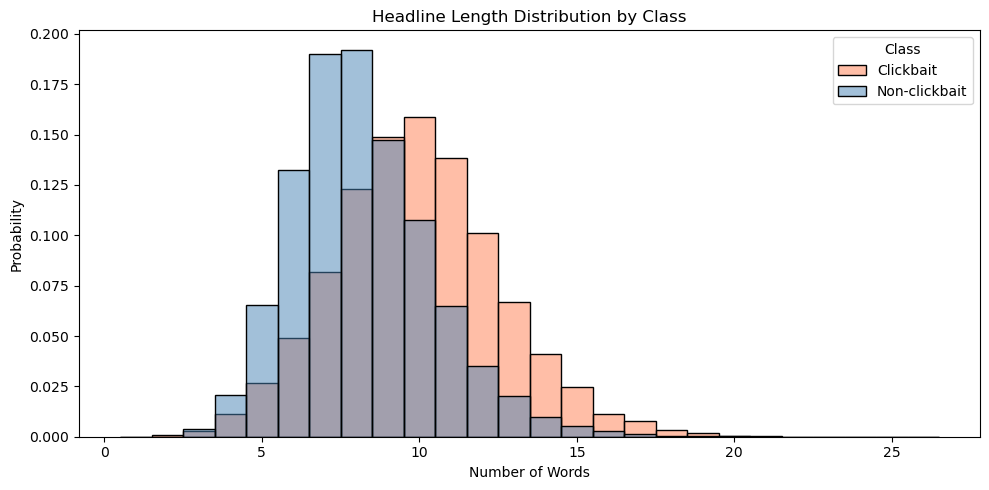

In [7]:
# Compare headline length distributions
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="label",
    discrete=True,
    stat="probability",
    common_norm=False,
    palette={0: "steelblue", 1: "coral"},
    alpha=0.5
)

plt.title("Headline Length Distribution by Class")
plt.xlabel("Number of Words")
plt.ylabel("Probability")
plt.legend(
    title="Class",
    labels=["Clickbait", "Non-clickbait"]
)
plt.tight_layout()
plt.show()

**Findings:**

- Clickbait headlines are approximately 21.4% longer on average than non-clickbait headlines (9.94 vs. 8.19 words).
- The distributions overlap considerably, suggesting that headline length alone is insufficient for reliable classification.
- The maximum observed headline length is 26 words.
- A sequence length of 32 tokens is proposed instead of the original 64, subject to verification after tokenisation.

## 4. Data Preparation

### 4.1 Data Splitting

Split the dataset into training (60%), validation (15%) and test (25%) sets using stratified sampling.   
Perform the split before tokenisation to prevent data leakage and preserve class proportions.

In [8]:
# Define input and target variables
X = df["headline"]
y = df["label"]

# Split into development and test sets
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

# Split development set into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_dev
)

# Display dataset sizes
print(f"Training samples: {len(X_train):,}")
print(f"Validation samples: {len(X_val):,}")
print(f"Test samples: {len(X_test):,}")

Training samples: 19,200
Validation samples: 4,800
Test samples: 8,000


### 4.2 Text Tokenisation

Convert headlines into numerical sequences using a tokeniser fitted exclusively on the training set to prevent data leakage.   
Out-of-vocabulary words are represented by a special OOV token.

In [9]:
# Tokeniser configuration
num_words = 20000

tokenizer = Tokenizer(
    num_words=num_words,
    oov_token="<OOV>"
)

# Build vocabulary using training data only
tokenizer.fit_on_texts(X_train)

# Convert headlines into numerical sequences
train_sequences = tokenizer.texts_to_sequences(X_train)
val_sequences = tokenizer.texts_to_sequences(X_val)
test_sequences = tokenizer.texts_to_sequences(X_test)

# Display vocabulary size
print(f"Vocabulary size: {len(tokenizer.word_index):,}")

Vocabulary size: 18,984


### 4.4 Sequence Padding

Standardise the input sequences to a fixed length of 32 tokens using post-padding and post-truncation.

In [10]:
# Define maximum sequence length
max_length = 32

# Pad training, validation and test sequences
X_train = pad_sequences(
    train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    val_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

# Display input dimensions
print(f"Training shape: {X_train.shape}")
print(f"Validation shape: {X_val.shape}")
print(f"Test shape: {X_test.shape}")

# Check potential information loss in training data
truncated_count = sum(
    len(seq) > max_length for seq in train_sequences
)

print(f"Truncated training sequences: {truncated_count}")

Training shape: (19200, 32)
Validation shape: (4800, 32)
Test shape: (8000, 32)
Truncated training sequences: 0


**Findings:**

- All input sequences have a fixed length of 32 tokens.
- No training sequences were truncated.
- The sequence length was reduced from 64 to 32
  without losing information from training sequences.

## 5. Model Development

### 5.1 Model Architecture

Build an LSTM-based neural network for binary text classification.   
The model consists of an embedding layer, an LSTM layer, a fully connected layer, dropout regularisation and a sigmoid output layer.

In [11]:
# Reset model state and ensure reproducibility
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

# Model configuration
embedding_dim = 64

# Build the LSTM model
model = Sequential([
    tf.keras.Input(shape=(max_length,)),
    Embedding(
        input_dim=num_words,
        output_dim=embedding_dim,
        mask_zero=True
    ),
    LSTM(128, dropout=0.2),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 32, 64)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,387,137 (5.29 MB)

 Trainable params: 1,387,137 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

### 5.2 Model Compilation

Compile the model using the Adam optimiser, binary cross-entropy loss and accuracy as the evaluation metric.

In [12]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

### 5.3 Model Training

Train the model using the training set and monitor its performance on the validation set.   
Apply early stopping based on validation loss to reduce overfitting and restore the best model weights.

In [13]:
# Configure early stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 30s 81ms/step - accuracy: 0.9435 - loss: 0.1563 - val_accuracy: 0.9794 - val_loss: 0.0582
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 24s 80ms/step - accuracy: 0.9905 - loss: 0.0293 - val_accuracy: 0.9790 - val_loss: 0.0617
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 28s 93ms/step - accuracy: 0.9982 - loss: 0.0068 - val_accuracy: 0.9804 - val_loss: 0.0782
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 85ms/step - accuracy: 0.9992 - loss: 0.0025 - val_accuracy: 0.9808 - val_loss: 0.0912
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


## 6. Model Evaluation

### 6.1 Test Set Evaluation

Evaluate the trained model on the held-out test set to assess its generalisation performance.

In [14]:
# Evaluate the model on the test set
results = model.evaluate(X_test, y_test, verbose=1)

print(f"Test Loss: {results[0]:.4f} "
      f"Test Accuracy: {results[1] * 100:.2f}%")

250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9778 - loss: 0.0634
Test Loss: 0.0634 Test Accuracy: 97.78%


### 6.2 Training and Validation Performance

Visualise training and validation accuracy and loss across epochs to assess learning dynamics and identify potential overfitting.

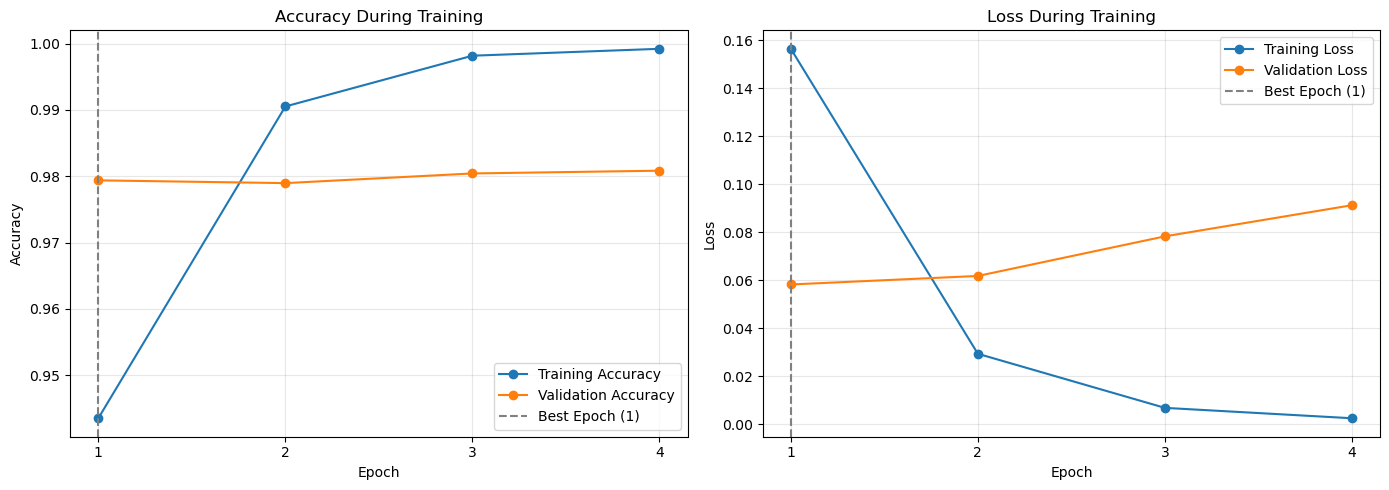

In [15]:
# Define epoch numbers
epochs = range(1, len(history.history["loss"]) + 1)
best_epoch = np.argmin(history.history["val_loss"]) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(epochs, history.history["accuracy"],
             marker="o", label="Training Accuracy")
axes[0].plot(epochs, history.history["val_accuracy"],
             marker="o", label="Validation Accuracy")
axes[0].set_title("Accuracy During Training")
axes[0].set_ylabel("Accuracy")

# Loss
axes[1].plot(epochs, history.history["loss"],
             marker="o", label="Training Loss")
axes[1].plot(epochs, history.history["val_loss"],
             marker="o", label="Validation Loss")
axes[1].set_title("Loss During Training")
axes[1].set_ylabel("Loss")

# Common formatting
for ax in axes:
    ax.axvline(best_epoch, color="grey", linestyle="--",
               label=f"Best Epoch ({best_epoch})")
    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Findings:**

- Validation accuracy remained stable at approximately 98%.
- Increasing validation loss after the first epoch indicates overfitting.
- Early stopping terminated training after four epochs and restored the weights from the first epoch.
- The selected model achieved a test accuracy of 97.78% and a test loss of 0.0634.

### 6.3 Classification Report

Evaluate classification performance for each class using precision, recall and F1-score.   
Convert predicted probabilities into binary class labels using a classification threshold of 0.5.

In [16]:
# Generate predicted probabilities
y_pred_proba = model.predict(X_test, verbose=0).ravel()

# Convert probabilities into binary class labels
y_pred = (y_pred_proba >= 0.5).astype(int)

# Display classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-clickbait", "Clickbait"],
    digits=4
))

               precision    recall  f1-score   support

Non-clickbait     0.9814    0.9740    0.9777      4000
    Clickbait     0.9742    0.9815    0.9778      4000

     accuracy                         0.9778      8000
    macro avg     0.9778    0.9778    0.9777      8000
 weighted avg     0.9778    0.9778    0.9777      8000



**Findings:**

- The model demonstrates balanced classification performance across both classes.
- Precision and recall exceed 97% for both classes.
- F1-scores are nearly identical: 97.77% for Non-clickbait and 97.78% for Clickbait.
- Neither class shows a substantial performance disadvantage.

### 6.4 Confusion Matrix

Visualise correct and incorrect predictions to examine classification errors across both classes.

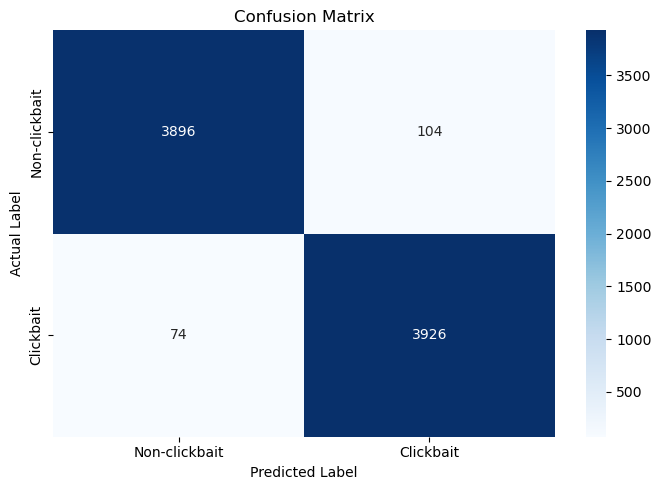

In [17]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualise confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-clickbait", "Clickbait"],
    yticklabels=["Non-clickbait", "Clickbait"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

**Findings:**

- The model correctly classified 7,822 out of 8,000 headlines.
- 104 non-clickbait headlines were misclassified as clickbait (false positives).
- 74 clickbait headlines were misclassified as non-clickbait (false negatives).
- The overall misclassification rate was approximately 2.23%.

### 6.5 Misclassification Analysis

Examine misclassified headlines to identify potential error patterns and limitations of the model.   
Analyse false positives and false negatives separately.

In [18]:
# Create a DataFrame with test predictions
prediction_results = pd.DataFrame({
    "headline": df.loc[y_test.index, "headline"].to_numpy(),
    "actual_label": y_test.to_numpy(),
    "predicted_label": y_pred,
    "clickbait_probability": y_pred_proba
})

# Identify misclassified headlines
false_positives = prediction_results[
    (prediction_results["actual_label"] == 0) &
    (prediction_results["predicted_label"] == 1)
]

false_negatives = prediction_results[
    (prediction_results["actual_label"] == 1) &
    (prediction_results["predicted_label"] == 0)
]

pd.set_option("display.max_colwidth", None)
# Display misclassified examples
print(f"False Positives: {len(false_positives)}")
display(false_positives.sample(5, random_state=RANDOM_STATE))

print(f"False Negatives: {len(false_negatives)}")
display(false_negatives.sample(5, random_state=RANDOM_STATE))

False Positives: 104


,headline,actual_label,predicted_label,clickbait_probability
2527,Tulsa media erroneously reports San Diego Comic Con Pedobear was 'registered sex offender',0,1,0.625378
4673,Pop starlet Kylie Minogue has early-stage breast cancer,0,1,0.979445
4579,The Older Audience Is Looking Better Than Ever,0,1,0.914975
3763,"Yeah, but What Has He Done Since the Derby?",0,1,0.801156
3314,A Plan to See Every Country on Earth by the Age of 35,0,1,0.736115


False Negatives: 74


,headline,actual_label,predicted_label,clickbait_probability
386,Sailor Senshi Imagined As Disney Princesses,1,0,0.390316
6277,A Best-Selling Author Dismissed Postpartum Depression Screening As A Pharmaceutical Conspiracy,1,0,0.148303
1613,Parseltongue Problems,1,0,0.488563
63,"Shaggy Returns With The Ultimate Diss Track, ""GFY""",1,0,0.085489
2317,Bad Driving School,1,0,0.353481


**Findings:**

- Some non-clickbait headlines contain emotional language, questions or curiosity-inducing expressions.
- Some clickbait headlines resemble conventional news headlines or use short, neutral expressions.
- Some incorrect predictions have high confidence scores.
- These examples suggest that distinguishing clickbait from non-clickbait based solely on headline text can be challenging.

## 7. Model Inference

Demonstrate the practical application of the trained model by classifying new, manually created headlines.   
Apply the same tokenisation and padding procedures used during model training.

In [19]:
def predict_clickbait(headlines):
    # Tokenise and pad new headlines
    sequences = tokenizer.texts_to_sequences(headlines)

    padded = pad_sequences(
        sequences,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    # Generate predictions
    probabilities = model.predict(padded, verbose=0).ravel()

    return pd.DataFrame({
        "headline": headlines,
        "clickbait_probability": probabilities.round(4),
        "predicted_class": np.where(
            probabilities >= 0.5,
            "Clickbait",
            "Non-clickbait"
        )
    })

In [20]:
# Example headlines
new_headlines = [
    "10 Things You Should Never Do Before Going to Bed",
    "You Won't Believe What Happened Next",
    "This Simple Trick Will Change Your Life Forever",
    "Scientists Discover a New Species of Marine Fish",
    "Government Announces New Education Policy",
    "Central Bank Keeps Interest Rates Unchanged"
]

predict_clickbait(new_headlines)

,headline,clickbait_probability,predicted_class
0,10 Things You Should Never Do Before Going to Bed,1.0000,Clickbait
1,You Won't Believe What Happened Next,0.9995,Clickbait
2,This Simple Trick Will Change Your Life Forever,0.9989,Clickbait
3,Scientists Discover a New Species of Marine Fish,0.0396,Non-clickbait
4,Government Announces New Education Policy,0.0017,Non-clickbait
5,Central Bank Keeps Interest Rates Unchanged,0.0040,Non-clickbait


**Findings:**

- All six example headlines were classified as expected.
- The model successfully distinguished typical clickbait expressions from neutral news headlines.
- The results demonstrate the practical applicability of the trained model on illustrative examples.

## 8. Model Saving

Save the trained model, fitted tokeniser and preprocessing configuration to enable future inference without retraining.

In [21]:
import json

# Create a directory for model artifacts
MODEL_DIR = Path("artifacts")
MODEL_DIR.mkdir(exist_ok=True)

# Save the trained model
model.save(MODEL_DIR / "clickbait_lstm.keras")

# Save the fitted tokeniser
with open(MODEL_DIR / "tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

# Save preprocessing configuration
config = {
    "num_words": num_words,
    "max_length": max_length,
    "padding": "post",
    "truncating": "post",
    "threshold": 0.5,
    "class_labels": {
        "0": "Non-clickbait",
        "1": "Clickbait"
    }
}

with open(MODEL_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

print("Model and preprocessing artifacts saved successfully.")

Model and preprocessing artifacts saved successfully.


## 9. Conclusion and Limitations

### Conclusion

An LSTM-based model was developed for binary classification of clickbait and non-clickbait headlines.

**Key results:**

- Dataset: 32,000 headlines.
- Test accuracy: 97.78%.
- Test loss: 0.0634.
- Weighted F1-score: 97.77%.
- Correct predictions: 7,822 out of 8,000.
- Training completed in four epochs using early stopping.

The model demonstrated balanced classification performance across both classes.   
The trained model and preprocessing artifacts were saved to enable future inference without retraining.

### Limitations

- The model relies exclusively on headline text, without considering article content or context.
- Ambiguous headlines may be difficult to classify.
- Generalisation to other news sources and more recent headlines has not been independently validated.

### Future Improvements

- Compare LSTM performance with traditional machine learning and transformer-based models.
- Evaluate performance on external datasets.
- Develop an interactive application for real-time headline classification.